In [1]:
import pandas as pd
from prettytable import PrettyTable
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib

RANDOM_STATE = 42

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Membaca dan Memahami Data

In [6]:
# masukkan data ke variabel
df = pd.read_csv('/content/drive/MyDrive/Data Science & Data Analysis/BankChurners/BankChurners.csv')

In [7]:
# lihat data dengan .head (teratas)
df.head(7)

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
2,15574012,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
3,15656148,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
4,15737452,653,Germany,Male,58,1,132602.88,1,1,0,5097.67,1
5,15699309,510,Spain,Female,38,4,0.00,1,1,0,118913.53,1
6,15589475,591,Spain,Female,39,3,0.00,3,1,0,140469.38,1


In [8]:
# melihat data secara acak
df.sample(5)

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
2720,15689096,590,France,Male,47,0,117879.32,1,1,1,8214.46,0
1182,15729224,710,France,Female,37,5,0.00,2,1,0,115403.31,0
2901,15590286,611,France,Female,40,2,125879.29,1,1,0,93203.43,0
2836,15725094,623,France,Female,37,4,140211.88,1,1,1,93832.33,0
6265,15632446,667,France,Male,24,4,0.00,2,0,0,180329.83,0


Berdasarkan dataset **Bank Customer Churn** berikut adalah penjelasan dari masing-masing kolom (*feature*) yang digunakan:

---

### **Daftar Feature / Kolom Dataset**

1. **`customer_id`**
* **Deskripsi:** Nomor identifikasi atau nomor akun unik untuk setiap nasabah.
* **Keterangan:** Variabel ini biasanya tidak digunakan sebagai input untuk model prediktif karena bersifat unik per individu dan tidak memberikan pola perilaku.


2. **`credit_score`**
* **Deskripsi:** Skor kredit nasabah.
* **Keterangan:** Menggambarkan tingkat kelayakan kredit atau riwayat finansial nasabah. Semakin tinggi skornya, semakin baik riwayat kredit nasabah tersebut.


3. **`country`**
* **Deskripsi:** Negara tempat tinggal nasabah (misalnya: Prancis, Jerman, Spanyol).
* **Keterangan:** Digunakan untuk melihat apakah lokasi geografis mempengaruhi tingkat perpindahan nasabah (*churn*).


4. **`gender`**
* **Deskripsi:** Jenis kelamin nasabah (Pria / Wanita).


5. **`age`**
* **Deskripsi:** Usia nasabah (dalam tahun).


6. **`tenure`**
* **Deskripsi:** Lama waktu (dalam tahun) nasabah tersebut telah menjadi nasabah atau memiliki rekening di bank ABC.


7. **`balance`**
* **Deskripsi:** Jumlah saldo atau sisa uang yang ada di rekening nasabah saat ini.


8. **`products_number`**
* **Deskripsi:** Jumlah produk bank (seperti rekening tabungan, kartu kredit, pinjaman, dll.) yang digunakan oleh nasabah tersebut.


9. **`credit_card`**
* **Deskripsi:** Status kepemilikan kartu kredit.
* **Keterangan:** Bernilai `1` jika nasabah memiliki kartu kredit, dan `0` jika tidak.


10. **`active_member`**
* **Deskripsi:** Status keaktifan nasabah di bank.
* **Keterangan:** Bernilai `1` jika nasabah aktif menggunakan layanan bank secara rutin, dan `0` jika tidak.


11. **`estimated_salary`**
* **Deskripsi:** Estimasi gaji tahunan nasabah yang tercatat di sistem bank.



---

### **Target Variabel**

12. **`churn`**
* **Deskripsi:** Kolom target (*label*) yang ingin diprediksi oleh model machine learning.
* **Keterangan:**
* **`1`**: Nasabah telah meninggalkan bank (menutup rekening/pindah) selama periode waktu tertentu.
* **`0`**: Nasabah tetap bertahan (tidak meninggalkan bank).

In [9]:
# melihat dimensi data
df.shape

(6399, 12)

In [10]:
# melihat informasi data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6399 entries, 0 to 6398
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       6399 non-null   int64  
 1   credit_score      6399 non-null   int64  
 2   country           6399 non-null   object 
 3   gender            6399 non-null   object 
 4   age               6399 non-null   int64  
 5   tenure            6399 non-null   int64  
 6   balance           6399 non-null   float64
 7   products_number   6399 non-null   int64  
 8   credit_card       6399 non-null   int64  
 9   active_member     6399 non-null   int64  
 10  estimated_salary  6399 non-null   float64
 11  churn             6399 non-null   int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 600.0+ KB


In [11]:
# melihat distribusi data numerik
df.describe()

,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,6.399000e+03,6399.000000,6399.000000,6399.000000,6399.000000,6399.000000,6399.000000,6399.000000,6399.000000,6399.000000
mean,1.569105e+07,649.729645,39.761838,4.984998,77814.904541,1.525082,0.703235,0.492421,100025.894654,0.318331
std,7.225964e+04,97.167749,10.504149,2.905045,62065.666419,0.618780,0.456868,0.499982,57458.091232,0.465865
min,1.556571e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,1.562864e+07,583.000000,33.000000,2.000000,0.000000,1.000000,0.000000,0.000000,51013.655000,0.000000
50%,1.569074e+07,651.000000,38.000000,5.000000,99056.220000,1.000000,1.000000,0.000000,100566.810000,0.000000
75%,1.575366e+07,718.000000,45.000000,7.000000,127766.085000,2.000000,1.000000,1.000000,149543.550000,1.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


**Interpretasi Deskriptif Statistic** <br>

**1. credit_score** <br>
- rata-rata credit score adalah 650.5
- median credit score adalah 652.0
- std adalah 96.65
- rentang daerah std (simpangan baku 68,2%) yakni 553.85 (mean - std) hingga 747.15 (mean + std)
- data credit score kemungkinan sedikit skew kiri. Dan rata-rata nasabah memiliki credit score dari kategori cukup - sangat baik

**2. age** <br>
- rata-rata usia adalah 39 tahun
- median usia adalah 37
- std usia adalah 10
- rentang daerah std yakni 29 tahun hingga 49 tahun
- data usia kemungkinan sedikit skew kanan.

**3. tenure** <br>
- rata-rata tenure adalah 5 tahun
- median tenure 5 tahun
- std tenure 2.9 tahun
- rentang daerah std yakni 2.1 tahun hingga 7.9 tahun
- data tenure kemungkinan besar berdistribusi normal

**4. balance dalam dolar** <br>
- rata-rata balance adalah 76,485.9
- median balance 97,198.
- std balance 62,397.4
- rentang daerah std yakni 14,088.5 hingga 138,883.3
- data balance mengalami skew kiri

**5. product number** <br>
- mean adalah 1.5 (int = 1)
- median adalah 1
- std adalah 0.9
- rentang daerah std yakni 0.1 hingga 1.9
- data kemungkinan berdistribusi normal

**6. credit card** <br>
- mean adalah 0.7
- kemungkinan mayoritas nasabah memiliki credit card

**7. active member** <br>
- mean 0.5
- kemungkinan keseimbangan presentasi antara pengguna layanan aktif dan tidak aktif

**8. estimated salary (dolar)** <br>
- mean adalah 100,090.2
- median adalah 100,193.9
- std adalah 57,514.5
- rentang daerah std adalah 42,575.7 hingga 157,604.7
- kemungkinan data berdistribusi normal - sedikit skew kiri

---

## 2. Data Cleaning

Melakukan pembersihan data meliputi:
1. Missing values
2. Duplicated data
3. Incorrect data
4. Saved cleaned data at .csv format

---

In [12]:
# melihat data kosong (bisa pakai isna atau isnull - keduanya function, wajib ada kurung)
df.isna().sum()

,0
customer_id,0
credit_score,0
country,0
gender,0
age,0
tenure,0
balance,0
products_number,0
credit_card,0
active_member,0


In [13]:
# melihat duplikasi data
df.customer_id.duplicated().sum()

np.int64(0)

In [14]:
# melihat kesalahan format pada data berformat object
# 1. country
df.country.unique()

array(['France', 'Spain', 'Germany'], dtype=object)

In [15]:
# 2. Gender
df.gender.unique()

array(['Female', 'Male'], dtype=object)

**note :** <br>

Dari hasil pemeriksaan data mentah, tidak terdapat missing values, duplikasi data, maupun kesalahan format. Tidak diperlukan pembersihan tahap awal.

---

## 3. Exploratory Data Analysis

Pada tahap ini dilakukan explorasi tahap lanjut:
1. Data distribution by visualization
2. Outlier by boxplot
3. Correlation heatmap
4. Category distribution visualization
5. Summary of EDA

---

In [16]:
# 0. Persiapkan data yang akan di analisis
# Kecualikan customer_id, country, gender, credit card, active member

df_used_columns = df.drop(columns=['customer_id', 'country', 'gender', 'credit_card', 'active_member'])
df_used_columns.columns

Index(['credit_score', 'age', 'tenure', 'balance', 'products_number',
       'estimated_salary', 'churn'],
      dtype='object')

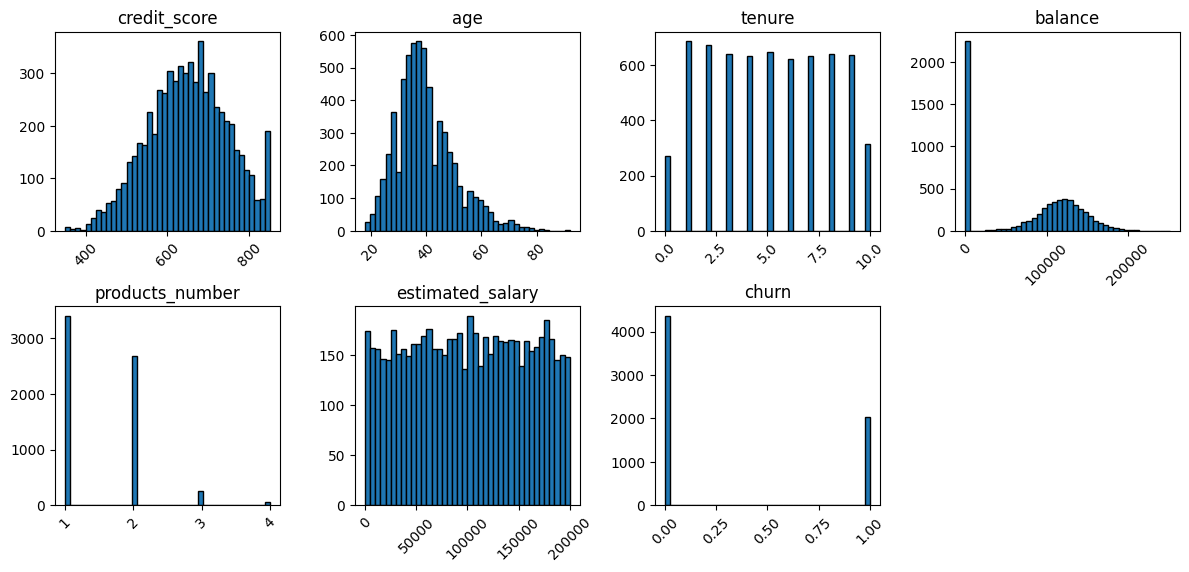

In [17]:
# 1. Data distribution by visualization
df_used_columns.hist(bins=40, xrot=45, grid=False, edgecolor='black', layout=(3, 4), figsize=(12, 8))
plt.tight_layout()
plt.show()

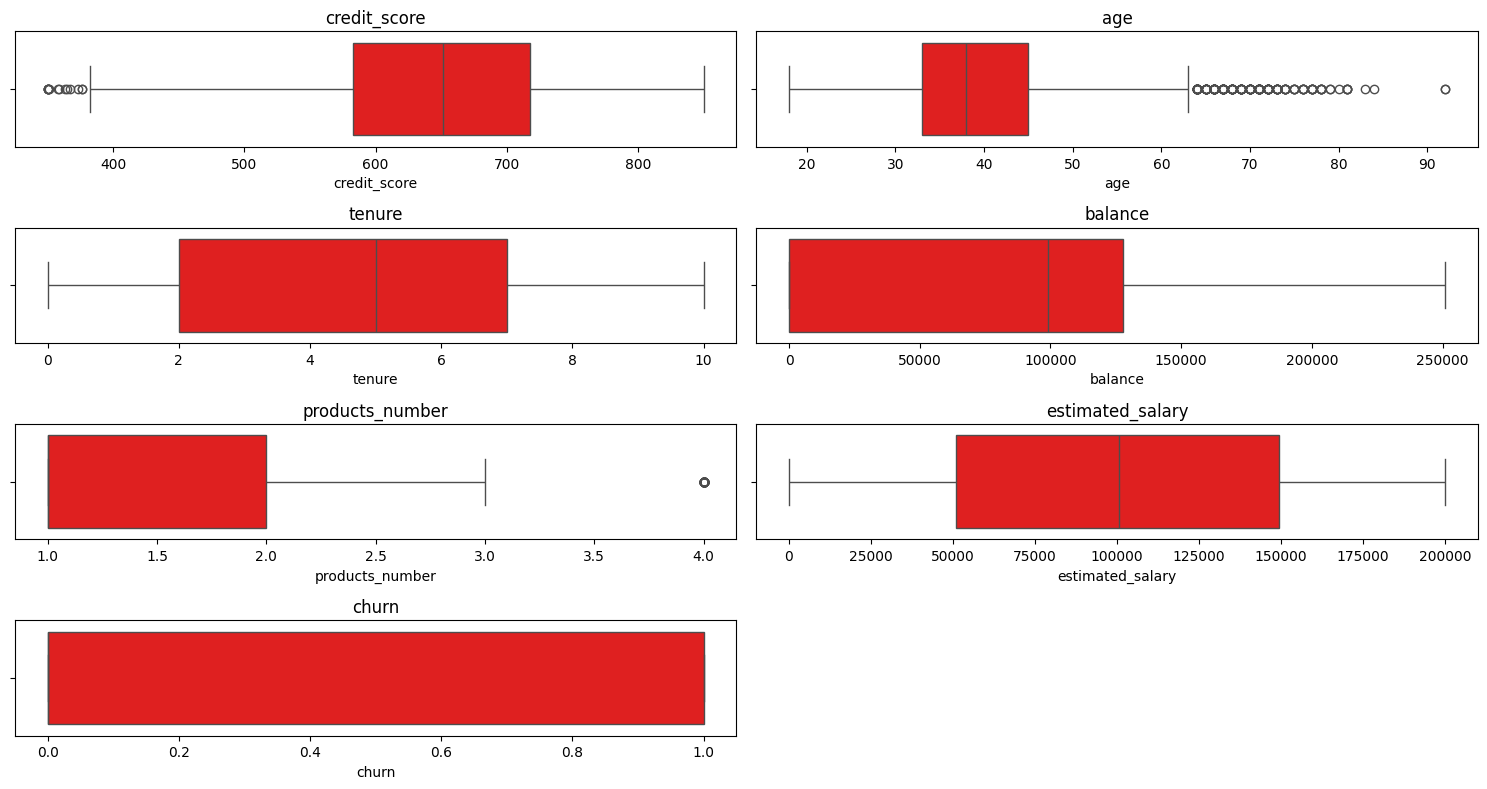

In [18]:
# 2. Outlier by boxplot
plt.figure(figsize=(15,8))
for i, col in enumerate(df_used_columns.columns):
  plt.subplot(4, 2, i+1)
  sns.boxplot(x=df_used_columns[col], color='red')
  plt.title(col)
plt.tight_layout()
plt.show()

<Axes: >

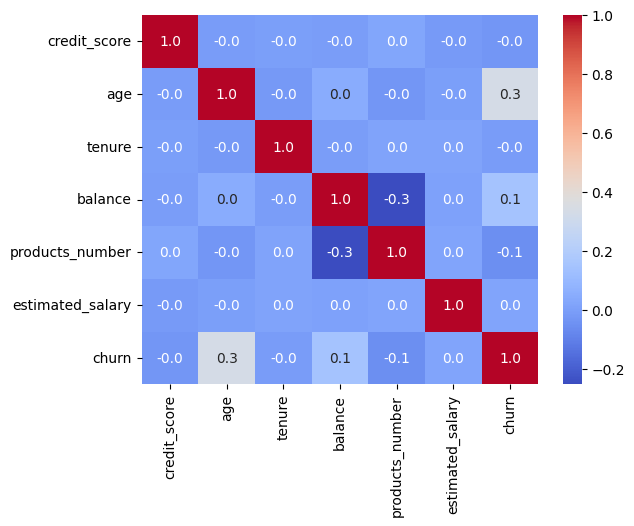

In [19]:
# 3. Heatmap correlation
sns.heatmap(df_used_columns.corr(), annot=True, cmap='coolwarm', fmt='.1f')

In [20]:
df.country.unique()

array(['France', 'Spain', 'Germany'], dtype=object)

<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

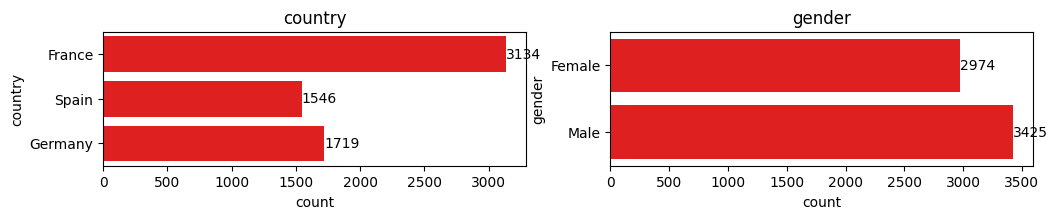

In [21]:
# 4. Categorical Distribution by Visualization
# 4.a Country & Gender
categorical = df.select_dtypes(include='object').columns
plt.figure(figsize=(12,8))
for i, col in enumerate(categorical, 1):
  plt.subplot(4, 2, i)
  ax = sns.countplot(y=df[col], color='red')
  ax.bar_label(ax.containers[0])
  plt.title(col)
plt.tight_layout

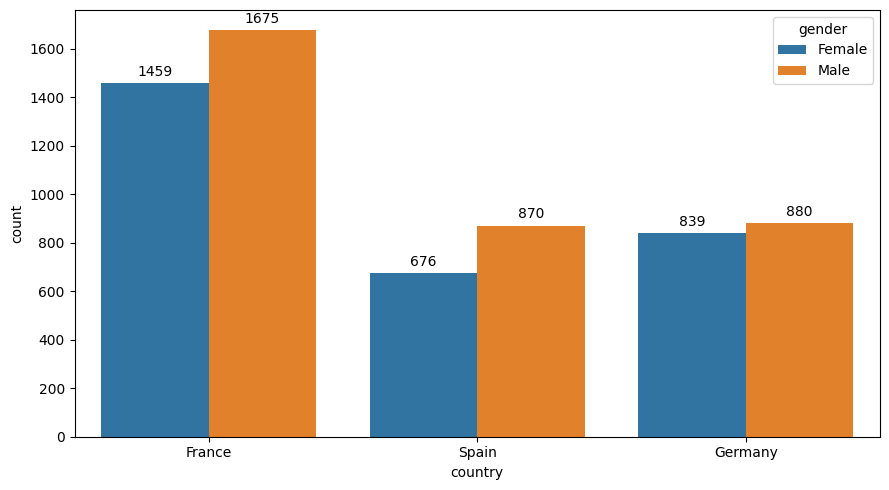

In [22]:
# 4.b Distribusi gender masing2 country
plt.figure(figsize=(9,5))
ax = sns.countplot(df, x="country", hue="gender")

ax.bar_label(ax.containers[0], padding=3)
ax.bar_label(ax.containers[1], padding=3)
plt.tight_layout()
plt.show()

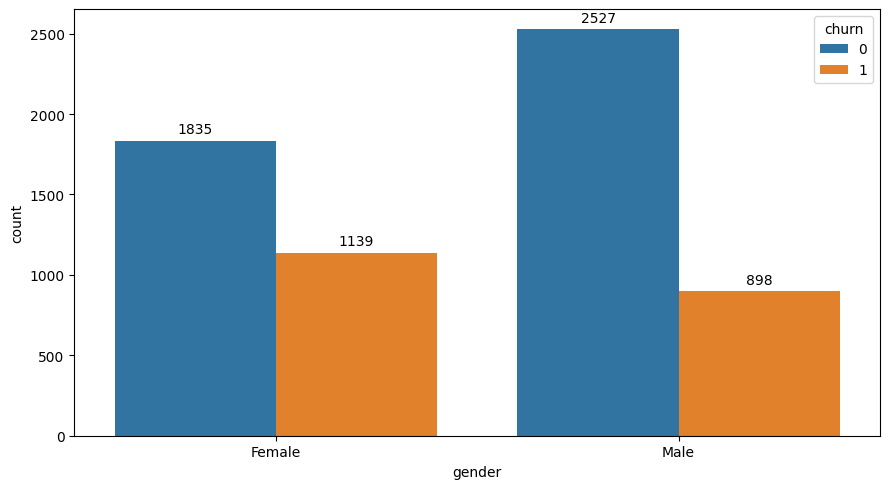

In [23]:
# 4.c Distribusi gender terhadap churn
plt.figure(figsize=(9,5))
ax = sns.countplot(df, x="gender", hue="churn")

ax.bar_label(ax.containers[0], padding=3)
ax.bar_label(ax.containers[1], padding=3)
plt.tight_layout()
plt.show()

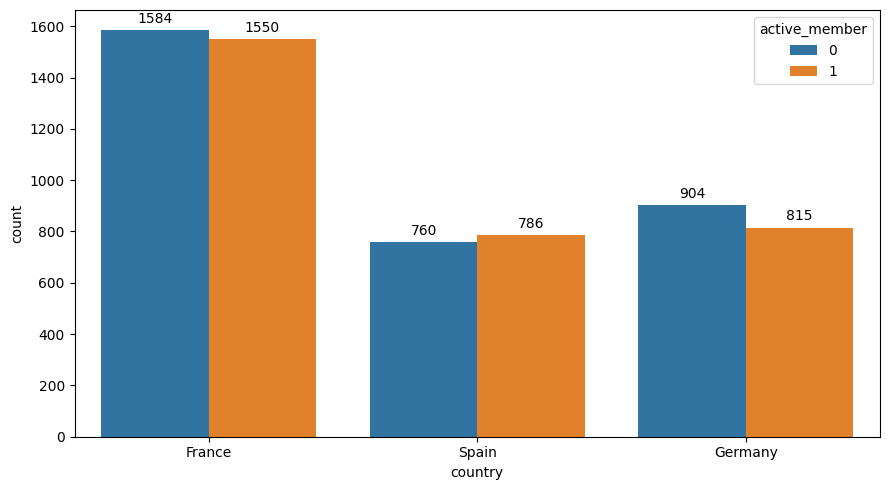

In [24]:
# 4.d Distribusi country terhadap active member
plt.figure(figsize=(9,5))
ax = sns.countplot(df, x="country", hue="active_member")

ax.bar_label(ax.containers[0], padding=3)
ax.bar_label(ax.containers[1], padding=3)
plt.tight_layout()
plt.show()

**summary of EDA** <br>

---

1. Data distribution by visualization
menurut hasil visualisasi data numerik memang mayoritas tidak terdistribusi normal

2. Outlier by boxplot
terdapat outlier pada feature credit_score dan age. Pada credit score outlier ada pada category creadit score rendah (under 400), dan pada age outlier di usia nasabah lebih dari 60 tahun. Outlier ini tidak akan di drop karena tujuan Utama riset ini adalah untuk mengetahui pattern dan anomali churn (saran digunakan standarisasi atau log)

3. Heatmap correlation
tidak ada korelasi signifikan satu sama lain antar feature. Semua feature berdiri sendiri

4. Catgeorical Distribution
- Country & Gender
Negara France mendominasi distribusi nasabah (setara dengan jumlah Spain + Germany)
Nasabah Male mendominasi dibandingkan nasabah Female

- Distribusi Gender masing2 Country
Ketiga negara didominasi oleh nasabah Male

- Distribusi Gender terhadap Churn
Meskipun Female minoritas, namun menyumbah nasabah churn lebih banyak dibandingkan nasabah Male

- Distribusi Gender terhadap Active Member
France dan Spain didominasi oleh nasabah aktif, sementara German didominasi oleh non active member. Meskipun selisih terhitung tipis (13 nasabah)




## 4. Pre-Processing Data

Meliputi:
1. Pemahaman kebutuhan
2. Split data train test
3. Sampling (SMOTE)
3. Encoding
---

**Penggunaan model:** <br>
1. Menggunakan model Decision Tree
2. Tidak butuh scaling
3. Membutuhkan Encoding (Label Encoding)
4. Split (80:20)

In [25]:
# 1. Split Data Train & Test
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
2,15574012,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
3,15656148,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
4,15737452,653,Germany,Male,58,1,132602.88,1,1,0,5097.67,1


In [26]:
# Copy kolom yang akan digunakan untuk proses pelatihan
df_to_train = df.drop(columns=['customer_id'])
df_to_train.columns

Index(['credit_score', 'country', 'gender', 'age', 'tenure', 'balance',
       'products_number', 'credit_card', 'active_member', 'estimated_salary',
       'churn'],
      dtype='object')

In [27]:
x = df_to_train.drop(columns=['churn'])
y = df_to_train['churn']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

In [28]:
# Cek hasil
data_hasil = {
    'x_train': x_train,
    'y_train': y_train,
    'x_test': x_test,
    'y_test': y_test

}

for key, values in data_hasil.items():
  print(f"{key} : {values.shape}")

x_train : (5119, 10)
y_train : (5119,)
x_test : (1280, 10)
y_test : (1280,)


In [29]:
y_train.value_counts()

,count
churn,
0,3489
1,1630


In [30]:
# 2. Encoding use Label Encoding
# 2.1 make dictionary to save the encoders
encoders = {}

# 2.2 encoding data using loop for each columns
for col in x_train.columns:
  if x_train[col].dtype == 'object': # hanya jika tipe datanya adalah object
    le = LabelEncoder() # buat le untuk masing2 column agar tidak overide
    x_train[col] = le.fit_transform(x_train[col]) # endoding...
    encoders[col] = le # save ke dictionary encoders

print(encoders)

{'country': LabelEncoder(), 'gender': LabelEncoder()}


1. country (France = 0, Germany = 1, Spain = 2)
2. gender (female = 0, male = 1)

In [31]:
# SMOTE SAMPLING
smote = SMOTE(sampling_strategy='minority', random_state=RANDOM_STATE)
x_train_sm, y_train_sm = smote.fit_resample(x_train, y_train)

In [32]:
x_train_sm.shape

(6978, 10)

In [33]:
# Save encoders
joblib.dump(encoders, 'encoders.pkl')

['encoders.pkl']

## 5. Modelling & Training

Meliputi:
1. Persiapan model
2. Hyperparameter Tuning GridSearchCV
3. Training using tuning results
---

In [34]:
# 1. Model Preparation
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
param_grid = {
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search = GridSearchCV(dt, param_grid=param_grid, cv=5, scoring='accuracy')

In [36]:
# 2. Hyperparameter Tuning
def tuning_dt(tuner, data_train, target_train, data_test, target_test, encoder):
  data_test2 = data_test.copy()
  for col, encoder in encoder.items():
    data_test2[col] = encoder.transform(data_test2[col])

  tuner.fit(data_train, target_train)
  best_dt_ = tuner.best_estimator_
  target_pred = best_dt_.predict(data_test2)
  result = classification_report(target_test, target_pred)
  best_dt_params = tuner.best_params_
  print(result)
  return best_dt_params

tuning_dt(grid_search, x_train_sm, y_train_sm, x_test, y_test, encoders)

              precision    recall  f1-score   support

           0       0.85      0.77      0.81       873
           1       0.59      0.71      0.64       407

    accuracy                           0.75      1280
   macro avg       0.72      0.74      0.73      1280
weighted avg       0.77      0.75      0.76      1280



{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}

**Hasil dari Tuning** <br>

Hasil tuning menunjukkan:
1. kedalaman pohon: 10
2. Minimal sample daun: 4
3. minimal sample split: 10

In [37]:
y_train_sm.value_counts()

,count
churn,
0,3489
1,3489


In [42]:
n_samples = len(y_train_sm)
n_classes = 2

cw = n_samples / (n_classes * np.bincount(y_train))
cw = {
    '0' : cw[0],
    '1' : cw[1]
}

for key, values in cw.items():
  print(f"{key} : {values:.2f}")

0 : 1.00
1 : 2.14


In [43]:
# 3. Training Model
CLASS_WEIGHT = {0:1, 1:2.14}
decision_tree = DecisionTreeClassifier(criterion='gini', max_depth=10, min_samples_leaf=4, min_samples_split=10, random_state=RANDOM_STATE, class_weight=CLASS_WEIGHT)
decision_tree.fit(x_train, y_train)

DecisionTreeClassifier(class_weight={0: 1, 1: 2.14}, max_depth=10,
                       min_samples_leaf=4, min_samples_split=10,
                       random_state=42)

In [44]:
# 4. Save model .pkl
joblib.dump(decision_tree, 'decision_tree_for_churn_classification.pkl')

['decision_tree_for_churn_classification.pkl']

## 6. Testing and Evaluation

meliputi:
1. Encoding data test
2. Testing & evaluation
3. Visualizing COnfussion Matrix
4. Summary
5. Finalisasi data

In [45]:
# 1. Encoding data test
for col, encoder in encoders.items():
  x_test[col] = encoder.transform(x_test[col])

x_test.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
5568,766,0,0,45,6,0.00,2,0,0,147184.74
2531,687,0,0,34,9,125474.44,1,1,0,198929.84
5610,457,2,0,38,6,0.00,2,1,0,173219.09
3943,566,0,1,34,3,0.00,1,0,0,188135.69
5532,705,2,1,36,1,111629.29,1,1,1,21807.16


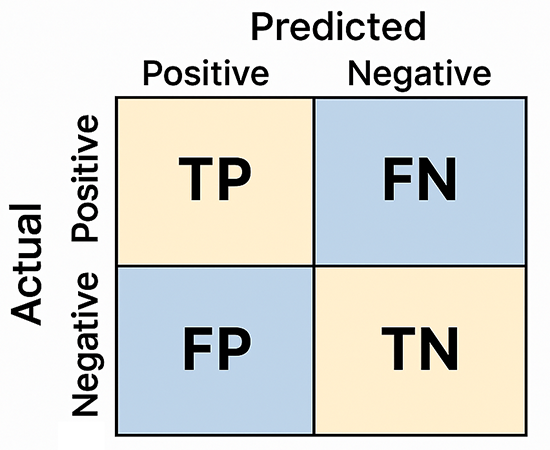

In [46]:
# 2. Testing and Evaluation
target_prediction = decision_tree.predict(x_test)
print("accuracy score :", accuracy_score(y_test, target_prediction))
print('==============================================')
print(classification_report(y_test, target_prediction))
print("==============================================")
print("confusion matrix :\n", confusion_matrix(y_test, target_prediction))

accuracy score : 0.759375
              precision    recall  f1-score   support

           0       0.86      0.77      0.81       873
           1       0.60      0.73      0.66       407

    accuracy                           0.76      1280
   macro avg       0.73      0.75      0.74      1280
weighted avg       0.78      0.76      0.76      1280

confusion matrix :
 [[676 197]
 [111 296]]


In [47]:
cmx = confusion_matrix(y_test, target_prediction)
print(cmx[0][0])
print(cmx[0][1])
print(cmx[1][0])
print(cmx[1][1])

676
197
111
296


In [48]:
# 3.1 Visualizing Confussion Matrix use Table (prettytable)
# Define the header
table = PrettyTable(['','Predicted Positive', 'Predicted Negative'])

# Add row
table.add_row(['Actual Positive', cmx[0][0], cmx[0][1]])
table.add_row(['Actual Negative', cmx[1][0], cmx[1][1]])

print(table)

+-----------------+--------------------+--------------------+
|                 | Predicted Positive | Predicted Negative |
+-----------------+--------------------+--------------------+
| Actual Positive |        676         |        197         |
| Actual Negative |        111         |        296         |
+-----------------+--------------------+--------------------+


In [49]:
# 3.2 Visualizing Confussion Matrix use Table (Pandas)

table2 = {
    "Actual/Predicted" : ["Positive", "Negative"],
    "Positive" : [cmx[0][0], cmx[1][0]],
    "Negative" : [cmx[0][1], cmx[1][1]]
}

table2_df = pd.DataFrame(table2)
table2_df

,Actual/Predicted,Positive,Negative
0,Positive,676,197
1,Negative,111,296


Text(50.722222222222214, 0.5, 'Actual')

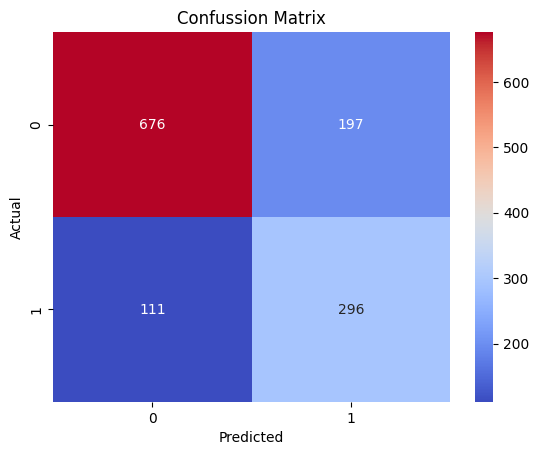

In [50]:
# 3.3 Visualizing Confussion Matrix use Heatmap
sns.heatmap(cmx, annot=True, cmap='coolwarm', fmt='.0f')
plt.title("Confussion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

**Summary :** <br>
1. Akurasi model saat evaluasi adalah 0.76
2. [Target 0 - No Churn] Precision 0.86 | Recall 0.77 | F1 Score 0.81
3. [Target 1 - Churn] Precision 0.60 | Recall 0.73 | F1 Score 0.66

Model masih cenderung bias pada target 0 (no churn) karena data imbalanced antara no churn nasabah vs churn nasabah. Precision (ketepatan) sebesar 60% berarti dari semua data atau sampel yang diprediksi positif oleh model, 60% di antaranya benar-benar positif, sementara 40% sisanya adalah kesalahan (False Positive).

**FINALISASI DATA HASIL TEST**

In [51]:
# 1. Inverse Encoding
for col, encoder in encoders.items():
  x_test[col] = encoder.inverse_transform(x_test[col])

x_test.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
5568,766,France,Female,45,6,0.00,2,0,0,147184.74
2531,687,France,Female,34,9,125474.44,1,1,0,198929.84
5610,457,Spain,Female,38,6,0.00,2,1,0,173219.09
3943,566,France,Male,34,3,0.00,1,0,0,188135.69
5532,705,Spain,Male,36,1,111629.29,1,1,1,21807.16


In [52]:
x_test_new = x_test.reset_index(drop=True) # reset index untuk mereset ulang index baris
target_col = pd.Series(target_prediction, name='churn').reset_index(drop=True)

In [ ]:
target_col

,churn
0,1
1,0
2,0
3,1
4,0
...,...
1275,1
1276,0
1277,0
1278,0


In [54]:
# 2. Join Tabel dengan hasil prediksi
data_join = pd.concat([x_test_new, target_col], axis=1)
data_join.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,766,France,Female,45,6,0.00,2,0,0,147184.74,1
1,687,France,Female,34,9,125474.44,1,1,0,198929.84,0
2,457,Spain,Female,38,6,0.00,2,1,0,173219.09,0
3,566,France,Male,34,3,0.00,1,0,0,188135.69,1
4,705,Spain,Male,36,1,111629.29,1,1,1,21807.16,0


In [55]:
# Save
data_join.to_csv("final_data_predicted.csv")

**TESTING**

In [57]:
# load model
model_dt_loaded = joblib.load('decision_tree_for_churn_classification.pkl')
encoder_load = joblib.load('encoders.pkl')

In [73]:
# Make a new data
data_new = {
    'credit_score' : [767, 567],
    'country' : ['France', 'Germany'],
    'gender' : ['Female', 'Male'],
    'age' : [45, 35],
    'tenure' : [6, 8],
    'balance' : [0.00, 150000.00],
    'products_number' : [2, 1],
    'credit_card' : [0, 1],
    'active_member' : [0, 1],
    'estimated_salary' : [147184.74, 178900.00]
}

data_new_df = pd.DataFrame.from_dict(data_new)
data_new_df

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
0,767,France,Female,45,6,0.0,2,0,0,147184.74
1,567,Germany,Male,35,8,150000.0,1,1,1,178900.00


In [74]:
# encoding data
for col, encoder in encoder_load.items():
  data_new_df[col] = encoder.transform(data_new_df[col])

data_new_df

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary
0,767,0,0,45,6,0.0,2,0,0,147184.74
1,567,1,1,35,8,150000.0,1,1,1,178900.00


In [78]:
def predict_churn(model, data):
  prediction = model.predict(data)
  print("Prediction : ", prediction)

predict_churn(model_dt_loaded, data_new_df)

Prediction :  [1 1]
